In [11]:
import sklearn
from matplotlib.image import imread
import os

from sklearn.cluster import KMeans

image = imread("../images/clustering_image.jpg")
image.shape

(908, 736, 3)

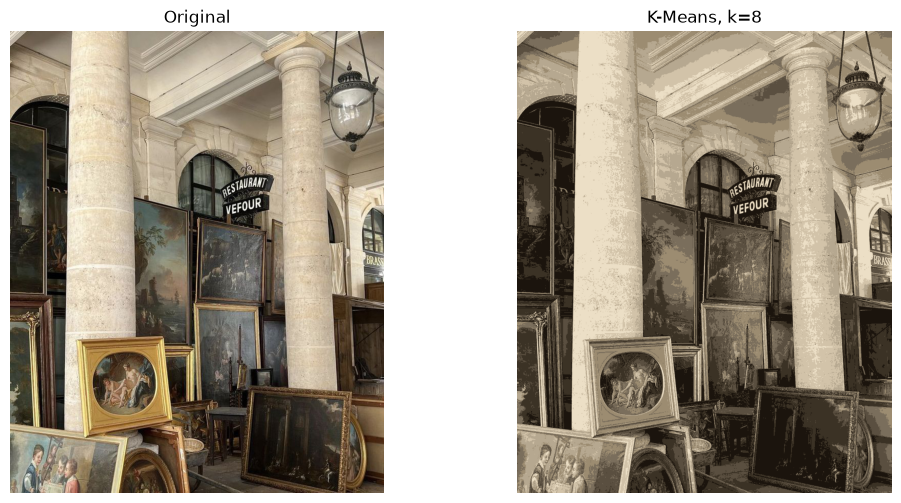

In [15]:
from sklearn.cluster import KMeans

X = image.reshape(-1, 3)
k_means = KMeans(n_clusters=8, random_state=42).fit(X)
segmented_image = k_means.cluster_centers_[k_means.labels_]
segmented_image = segmented_image.astype("uint8")
segmented_image = segmented_image.reshape(image.shape)

import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(image);            ax[0].set_title("Original")
ax[1].imshow(segmented_image);  ax[1].set_title("K-Means, k=8")
for a in ax:
    a.axis("off")
plt.show()

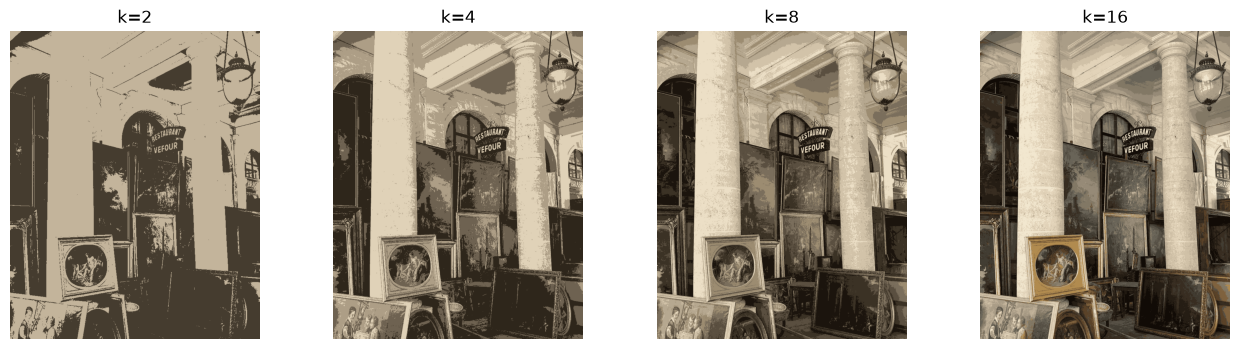

In [18]:
ks = [2, 4, 8, 16]
fig, axes = plt.subplots(1, len(ks), figsize=(16, 4))
for ax, k in zip(axes, ks):
   km = KMeans(n_clusters=k, random_state=42).fit(X)
   seg = km.cluster_centers_[km.labels_].reshape(image.shape).astype("uint8")
   ax.imshow(seg); ax.set_title(f"k={k}"); ax.axis("off")
plt.show()

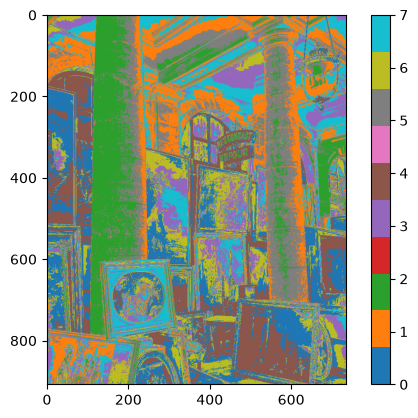

In [19]:
label_img = k_means.labels_.reshape(image.shape[:2])
plt.imshow(label_img, cmap="tab10"); plt.colorbar(); plt.show()

In [20]:
   plt.imsave("../outputs/segmented.png", segmented_image)